# Sequential-section registration

When two modalities come from **neighbouring sections** — spatial
metabolomics (SM, MALDI) on one section, spatial transcriptomics (ST, Xenium)
on the next — the tissue itself differs, so there is no one-to-one
correspondence between cells. SMINT registers them as images instead: it
rasterises both point clouds, and runs STalign's LDDMM (a smooth,
invertible deformation) initialised from a handful of landmarks you place by
hand. Every SM pixel then gets coordinates in the ST frame.

In this tutorial you will:

1. bring a mis-oriented synthetic SM section roughly into the ST frame with an
   orientation search (`build_pretransform` + `overlap_score`);
2. rasterise both sections for landmarking (`prepare_landmark_inputs`) and look
   at the landmarks;
3. register with `register_sm_to_st` (`orientation="stalign"`) and measure the
   error against the known truth;
4. register a downsampled real pair: Sample 2, Xenium section Z2 and MALDI
   section B, with its 11 landmarks.

**Runtime:** each registration took about 20 s on one NVIDIA A30 GPU. On a
CPU, LDDMM takes much longer — submit it as a job (see the end of this page).
**Requires:** an environment with STalign, which needs `numpy<2` and PyTorch.

**How this page was run:** executed top to bottom on a GPU node with
`jupyter nbconvert --execute`, from `docs/tutorials/`.

**Download this notebook:** [03_sequential_registration.ipynb](03_sequential_registration.ipynb)

In [1]:
import logging
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s",
                    stream=sys.stdout, force=True)

from smint.alignment import (
    apply_pretransform, build_pretransform, describe_pretransform, load_landmarks,
    overlap_score, prepare_landmark_inputs, read_sm_matrix, register_sm_to_st,
    sm_coordinates,
)

ST, SM = "#2b6cb0", "#d53f8c"


def overlay(ax, st_xy, sm_xy, title, st_points=None, sm_points=None):
    """ST cells in blue, SM pixels in pink, optional numbered landmarks."""
    ax.scatter(st_xy[:, 0], st_xy[:, 1], s=0.4, c=ST, alpha=0.6, lw=0)
    if sm_xy is not None:
        ax.scatter(sm_xy[:, 0], sm_xy[:, 1], s=0.4, c=SM, alpha=0.25, lw=0)
    for pts, colour in ((st_points, ST), (sm_points, SM)):
        if pts is not None:
            ax.scatter(pts[:, 0], pts[:, 1], s=60, marker="*", c="k")
            for i, (x, y) in enumerate(pts, 1):
                ax.annotate(str(i), (x, y), xytext=(4, 4), textcoords="offset points",
                            color=colour, fontsize=9, weight="bold")
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_title(title)

## 1. The synthetic pair

`synthetic_st.csv` holds ST cell centroids in microns (`x_final`, `y_final`).
`synthetic_sm.csv` holds SM pixels as raw pixel indices (`x`, `y`), like a
MALDI export. `read_sm_matrix` converts pixels to microns with `scale_xy`
(10 µm pixels here). Read without any rotation, the SM section lies on its side:

9,000 ST cells, 51,565 SM pixels


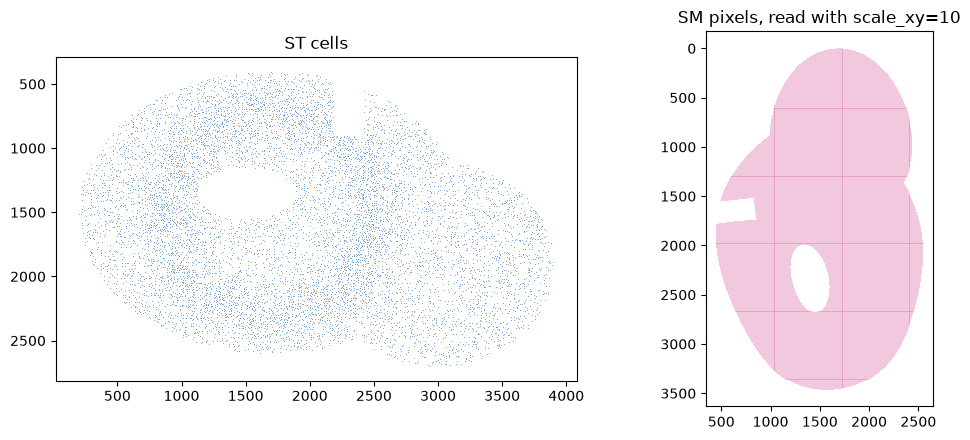

In [2]:
st = pd.read_csv("data/synthetic_st.csv")
st_xy = st[["x_final", "y_final"]].to_numpy()
sm_raw = read_sm_matrix("data/synthetic_sm.csv", scale_xy=10.0, verbose=False)
sm_raw_xy = sm_coordinates(sm_raw)
print(f"{len(st_xy):,} ST cells, {len(sm_raw_xy):,} SM pixels")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
overlay(axes[0], st_xy, None, "ST cells")
overlay(axes[1], np.empty((0, 2)), sm_raw_xy, "SM pixels, read with scale_xy=10")
plt.tight_layout(); plt.show()

## 2. Coarse pre-registration: find the orientation

`build_pretransform` builds a flip / rotation / scale about the source
centroid and moves it onto the target's centroid; `overlap_score` is the
fraction of 50 µm bins occupied by the target that the moved source also
occupies. Trying every 15° with and without flips and keeping the best score is
what `smint-alignment pretransform --search` does:

In [3]:
best = (-1.0, None)
for flip_x in (False, True):
    for flip_y in (False, True):
        for rotation in range(-180, 180, 15):
            matrix = build_pretransform(sm_raw_xy, st_xy, rotation=float(rotation),
                                        flip_x=flip_x, flip_y=flip_y)
            score = overlap_score(apply_pretransform(sm_raw_xy, matrix), st_xy)
            if score > best[0]:
                best = (score, dict(rotation=rotation, flip_x=flip_x, flip_y=flip_y))
score, settings = best
print(f"best: {settings}, overlap {score:.3f}")
matrix = build_pretransform(sm_raw_xy, st_xy, **settings)
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in describe_pretransform(matrix).items()}

best: {'rotation': 90, 'flip_x': False, 'flip_y': False}, overlap 0.921


{'scale_x': 1.068,
 'scale_y': 1.068,
 'rotation_deg': 90.0,
 'shear_deg': 0.0,
 'translation': (3839.6063820897325, -93.48855425776478),
 'determinant': 1.141,
 'reflects': False}

The search finds a 90° counter-clockwise rotation. That is the rotation MALDI
exports need relative to Xenium on this setup, and `read_sm_matrix` applies it
directly with `rotate_left_90=True`. The remaining few degrees, the scale
difference and the warp are left to the landmarks and LDDMM. The landmark
files below were placed in the frame that
`read_sm_matrix(scale_xy=10, rotate_left_90=True)` produces, so that is what
every later step passes.

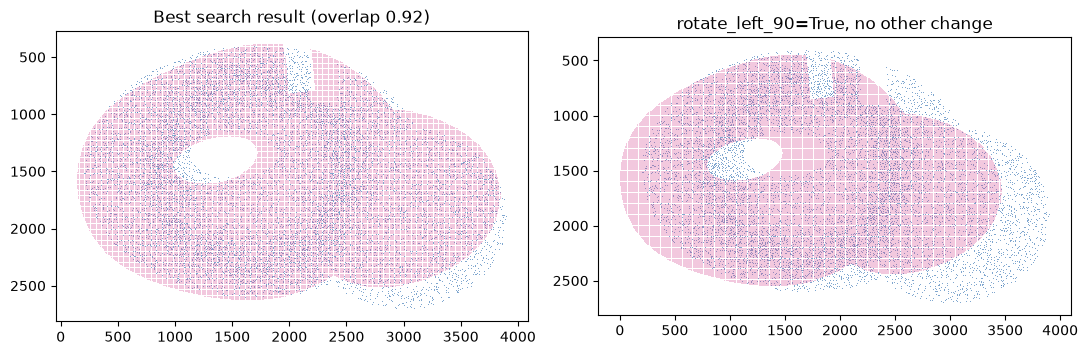

In [4]:
sm_kwargs = dict(scale_xy=10.0, rotate_left_90=True)
sm_xy = sm_coordinates(read_sm_matrix("data/synthetic_sm.csv", verbose=False, **sm_kwargs))
moved = apply_pretransform(sm_raw_xy, matrix)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
overlay(axes[0], st_xy, moved, f"Best search result (overlap {score:.2f})")
overlay(axes[1], st_xy, sm_xy, "rotate_left_90=True, no other change")
plt.tight_layout(); plt.show()

## 3. Landmarks

LDDMM needs a starting point: a few **landmarks**, the same recognisable
features picked in both sections in the same order (correspondence is by
position in the list). `prepare_landmark_inputs` rasterises both sections at
`dx` µm per pixel and writes the `.npz` images that STalign's
`point_annotator.py` opens; the SMINT napari plugin (**3. Landmarks**) does the
same interactively.

In [5]:
inputs = prepare_landmark_inputs(
    st_file="data/synthetic_st.csv",
    sm_file="data/synthetic_sm.csv",
    output_prefix="landmarks/synthetic",      # writes landmarks/synthetic_st.npz, _sm.npz
    dx=30.0,
    sm_kwargs=sm_kwargs,
)
{k: inputs[k] for k in ("st_npz", "sm_npz", "st_points", "sm_points")}

INFO: Using ST coordinate columns 'x_final' / 'y_final' from synthetic_st.csv


INFO: Read 9000 ST cells from synthetic_st.csv (x_final, y_final)


INFO: Reading matrix file: synthetic_sm.csv


INFO: Loaded 51565 rows, 2 columns


INFO: Rasterizing 9000 points at dx=30.0


...

INFO: Rasterized grid shape: ((1, 77, 127),)


INFO: Wrote rasterized image for annotation: landmarks/synthetic_st.npz


INFO: Wrote rasterized image for annotation: landmarks/synthetic_sm.npz


INFO: Phase 1 complete. Annotate both .npz files with point_annotator.py, picking the same landmarks in the same order in each:
  python point_annotator.py landmarks/synthetic_st.npz landmarks/synthetic_sm.npz
This writes landmarks/synthetic_st_points.npy and landmarks/synthetic_sm_points.npy, which register_sm_to_st() consumes.


{'st_npz': 'landmarks/synthetic_st.npz',
 'sm_npz': 'landmarks/synthetic_sm.npz',
 'st_points': 'landmarks/synthetic_st_points.npy',
 'sm_points': 'landmarks/synthetic_sm_points.npy'}

`point_annotator.py` saves each picked set as `<stem>_points.npy`, a
`{label: [(x, y)]}` dictionary. The tutorial data ships with 8 landmark pairs
in that format. `load_landmarks` reads them in STalign's **row-column**
`(y, x)` order, so swap the columns back to plot them:

INFO: Loaded 8 landmarks from synthetic_st_points.npy


INFO: Loaded 8 landmarks from synthetic_sm_points.npy


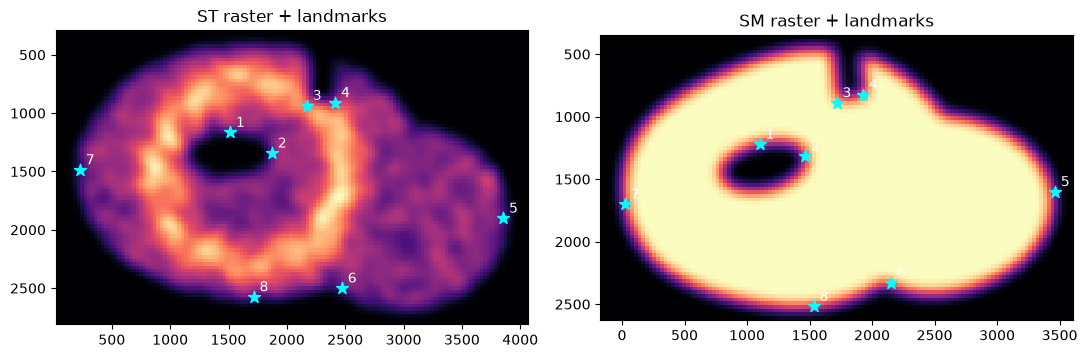

In [6]:
st_lm = load_landmarks("data/synthetic_st_points.npy")[:, ::-1]
sm_lm = load_landmarks("data/synthetic_sm_points.npy")[:, ::-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, key, pts, title in ((axes[0], "st_raster", st_lm, "ST raster + landmarks"),
                            (axes[1], "sm_raster", sm_lm, "SM raster + landmarks")):
    X, Y, I = inputs[key]
    ax.imshow(I[0], extent=(X[0], X[-1], Y[-1], Y[0]), cmap="magma")
    ax.scatter(pts[:, 0], pts[:, 1], s=80, marker="*", c="cyan")
    for i, (x, y) in enumerate(pts, 1):
        ax.annotate(str(i), (x, y), xytext=(4, 4), textcoords="offset points", color="w")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 4. Register

`register_sm_to_st` rasterises both sections again, runs LDDMM with the SM as
source and the ST as target, starting from the landmark fit, and transforms
every SM pixel. Pass **`orientation="stalign"`** to get true `(x, y)` in the ST
frame, which is what you want to overlay or join with the ST data.
(`lddmm_params={"draw": False}` turns off STalign's own progress figures.)

In [7]:
start = time.time()
registered = register_sm_to_st(
    st_file="data/synthetic_st.csv",
    sm_file="data/synthetic_sm.csv",
    st_points_file="data/synthetic_st_points.npy",
    sm_points_file="data/synthetic_sm_points.npy",
    sm_kwargs=sm_kwargs,
    orientation="stalign",
    output_path="registered/synthetic_sm_transformed.csv",
    lddmm_params={"draw": False},
)
print(f"registered {len(registered):,} SM pixels in {time.time() - start:.0f} s")
registered.head(3)

INFO: Using ST coordinate columns 'x_final' / 'y_final' from synthetic_st.csv


INFO: Read 9000 ST cells from synthetic_st.csv (x_final, y_final)


INFO: Reading matrix file: synthetic_sm.csv


INFO: Loaded 51565 rows, 2 columns


INFO: Rasterizing 9000 points at dx=30.0


...

INFO: Running LDDMM (niter=1000, epV=200.0, device=cuda:0, landmarks=8)


INFO: LDDMM alignment complete


INFO: Saved transformed data to registered/synthetic_sm_transformed.csv


registered 51,565 SM pixels in 12 s


,x,y,x_transformed,y_transformed
0,1440.0,450.0,1870.397187,421.432735
1,1450.0,450.0,1881.680520,422.980080
2,1460.0,450.0,1892.884538,424.545076


The output is the SM table with two columns added, `x_transformed` and
`y_transformed`; every other column (for real data, one per m/z) is kept.

The synthetic data comes with the true ST-frame position of every SM pixel, so
the error can be measured — and compared with what the landmarks alone give (a
least-squares affine through the 8 pairs):

In [8]:
truth = pd.read_csv("data/synthetic_sm_truth.csv")[["x_true", "y_true"]].to_numpy()
after = registered[["x_transformed", "y_transformed"]].to_numpy()

design = np.column_stack([sm_lm, np.ones(len(sm_lm))])
affine = np.linalg.lstsq(design, st_lm, rcond=None)[0]
landmarks_only = np.column_stack([sm_xy, np.ones(len(sm_xy))]) @ affine

for name, xy in (("landmark affine only", landmarks_only), ("LDDMM", after)):
    err = np.linalg.norm(xy - truth, axis=1)
    print(f"{name:>21}: median error {np.median(err):5.1f} um, 90th percentile {np.percentile(err, 90):5.1f} um")

 landmark affine only: median error  34.9 um, 90th percentile  56.1 um
                LDDMM: median error  28.5 um, 90th percentile  69.4 um


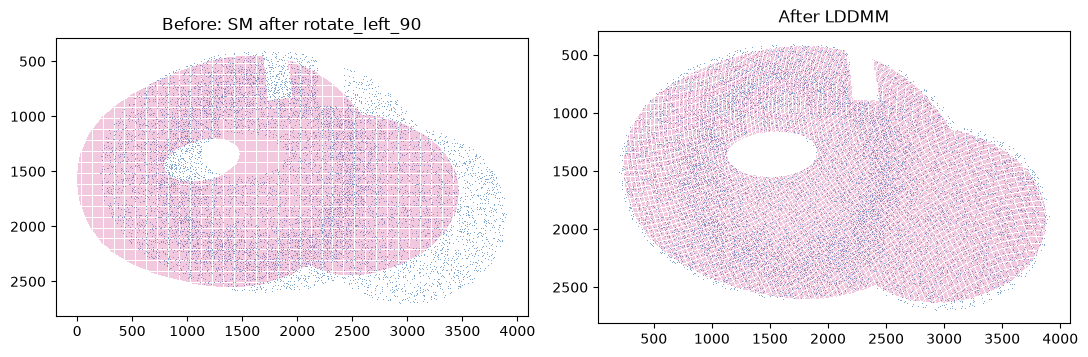

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
overlay(axes[0], st_xy, sm_xy, "Before: SM after rotate_left_90")
overlay(axes[1], st_xy, after, "After LDDMM")
plt.tight_layout(); plt.show()

LDDMM brings the median error below the landmark fit, to about one 30 µm
raster pixel — but not everywhere: compare the 90th percentiles. Coordinates
alone carry little information inside the tissue (the SM raster above is
flat), so LDDMM mostly matches the outline and the holes; the landmarks carry
the rest. Spread them over the whole section, on features you can find in both
modalities, and always check the overlay.

## 5. Real data: Sample 2, Xenium Z2 and MALDI section B

The real pair: 53,622 Xenium cells from section Z2, and a random quarter of
the MALDI pixels from neighbouring section B (coordinates only), with the
11 landmark pairs placed for this registration. The MALDI pixels need the
same `scale_xy=10` and `rotate_left_90=True`.

INFO: Loaded 11 landmarks from sample2_st_landmarks.npy


INFO: Loaded 11 landmarks from sample2_sm_landmarks.npy


53,622 ST cells, 115,502 SM pixels, 11 landmark pairs


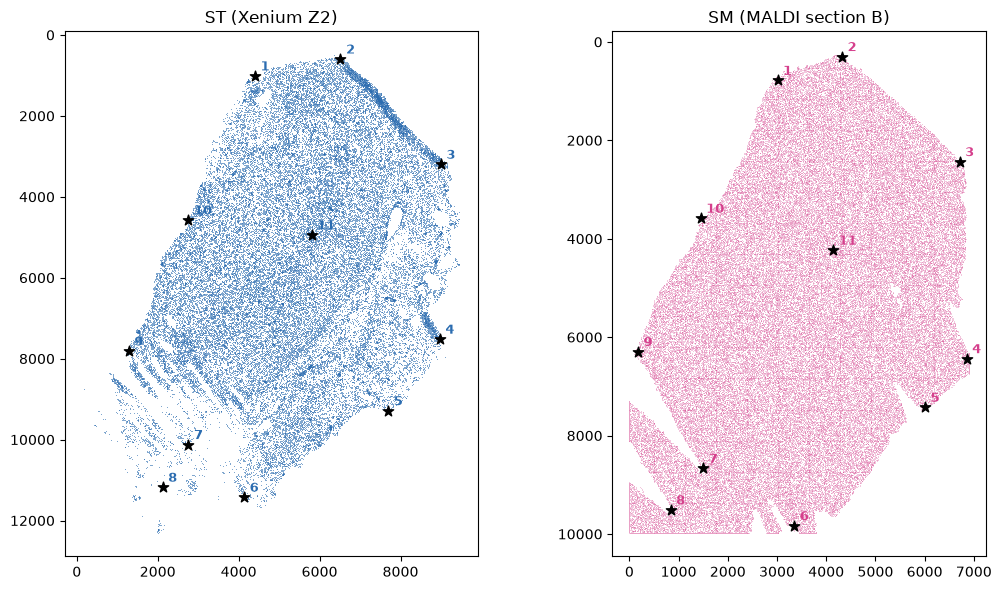

In [10]:
st_real = pd.read_csv("data/sample2_st_z2.csv")[["x_final", "y_final"]].to_numpy()
sm_real = sm_coordinates(read_sm_matrix("data/sample2_sm_sectionB.csv", verbose=False, **sm_kwargs))
st_lm = load_landmarks("data/sample2_st_landmarks.npy")[:, ::-1]
sm_lm = load_landmarks("data/sample2_sm_landmarks.npy")[:, ::-1]
print(f"{len(st_real):,} ST cells, {len(sm_real):,} SM pixels, {len(st_lm)} landmark pairs")

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
overlay(axes[0], st_real, None, "ST (Xenium Z2)", st_points=st_lm)
overlay(axes[1], np.empty((0, 2)), sm_real, "SM (MALDI section B)", sm_points=sm_lm)
plt.tight_layout(); plt.show()

In [11]:
start = time.time()
registered = register_sm_to_st(
    st_file="data/sample2_st_z2.csv",
    sm_file="data/sample2_sm_sectionB.csv",
    st_points_file="data/sample2_st_landmarks.npy",
    sm_points_file="data/sample2_sm_landmarks.npy",
    sm_kwargs=sm_kwargs,
    orientation="stalign",
    output_path="registered/sample2_sm_transformed.csv",
    lddmm_params={"draw": False},
)
print(f"registered {len(registered):,} SM pixels in {time.time() - start:.0f} s")

INFO: Using ST coordinate columns 'x_final' / 'y_final' from sample2_st_z2.csv


INFO: Read 53622 ST cells from sample2_st_z2.csv (x_final, y_final)


INFO: Reading matrix file: sample2_sm_sectionB.csv


INFO: Loaded 115502 rows, 2 columns


INFO: Rasterizing 53622 points at dx=30.0


...

INFO: Loaded 11 landmarks from sample2_sm_landmarks.npy


INFO: Running LDDMM (niter=1000, epV=200.0, device=cuda:0, landmarks=11)


INFO: LDDMM alignment complete


INFO: Saved transformed data to registered/sample2_sm_transformed.csv


registered 115,502 SM pixels in 17 s


There is no ground truth between two different sections. The practical checks
are the overlay, and how far each SM pixel lands from the nearest ST cell:

median distance to the nearest ST cell: 16.4 um


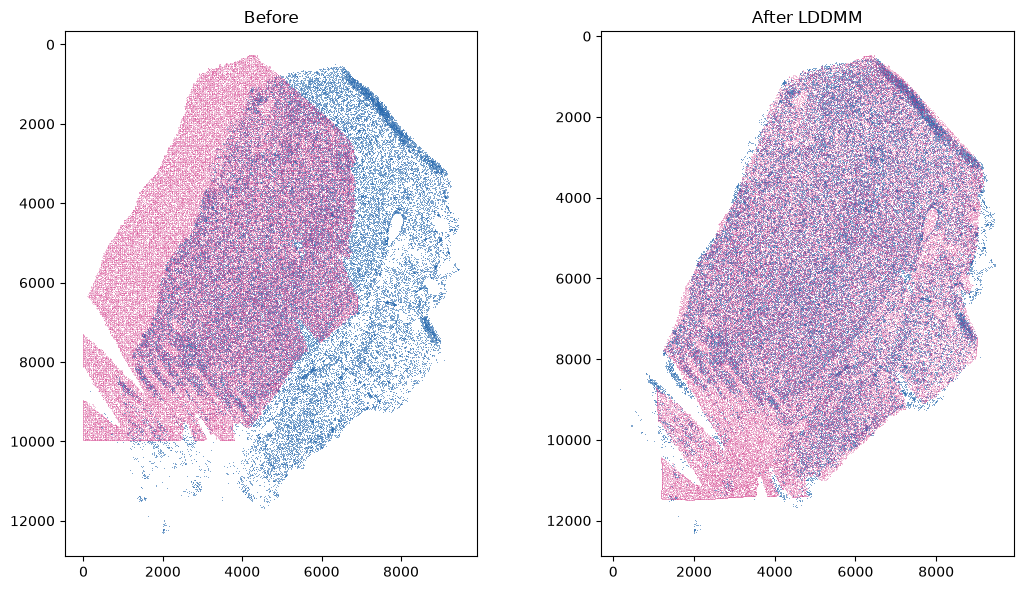

In [12]:
after = registered[["x_transformed", "y_transformed"]].to_numpy()
distance, _ = cKDTree(st_real).query(after)
print(f"median distance to the nearest ST cell: {np.median(distance):.1f} um")

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
overlay(axes[0], st_real, sm_real, "Before")
overlay(axes[1], st_real, after, "After LDDMM")
plt.tight_layout(); plt.show()

That is about half a 30 µm raster pixel, the same as the full-resolution
registration of this pair in the [worked examples](../../examples/#1-spatial-metabolomics-spatial-transcriptomics).

## Orientation: why `"stalign"`

STalign works in row-column order. `orientation="dataset"` — the default, kept
so older outputs can be reproduced — returns the two transformed axes the other
way round, transposed relative to the ST cells. Swapping the columns of the
result above shows what that looks like over the ST data: like a failed
registration, although the registration is fine.

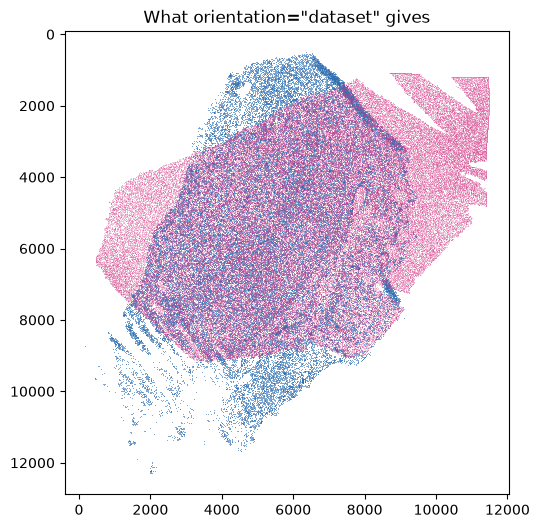

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 6))
overlay(ax, st_real, after[:, ::-1], 'What orientation="dataset" gives')
plt.tight_layout(); plt.show()

## Run it as a job

LDDMM belongs on a GPU node. From a login node, the command line builds the
job, submits it with `sbatch` and, with `--watch`, waits for the result. Point
`--worker-python` at the environment that has STalign:

```bash
smint-alignment st-sm \
    --st data/sample2_st_z2.csv \
    --sm data/sample2_sm_sectionB.csv \
    --st-points data/sample2_st_landmarks.npy \
    --sm-points data/sample2_sm_landmarks.npy \
    --rotate-left-90 --orientation stalign \
    --output-dir sample2_z2_registration \
    --submit --watch --partition gpuq --gpus 1 --memory 64G \
    --worker-python /path/to/stalign-env/bin/python
```

The output directory must be on storage the compute node can see. The napari
plugin's **4. Register** widget submits the same job. See
[Running on HPC](../../hpc_deployment/).

## Next steps

- [Choosing a registration method](../../concepts/registration_methods/) —
  sequential versus same-section data.
- [Coordinate frames](../../concepts/coordinate_frames/) — pixels, microns
  and the orientation conventions in detail.
- [napari plugin](../../napari_plugin/) — pre-register and place landmarks by eye.